# house prices in sri lanka

goal is to predict the asking price of a house for sale in sri lanka. data is the ikman.lk property ads dataset from kaggle (ivantha).

In [1]:
import os, io, glob, ast, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

## 1. getting the data

downloaded with kagglehub into `../data/raw`. that folder is ignored by git, only the cleaned file gets saved in the repo.

In [2]:
os.environ['KAGGLEHUB_CACHE'] = '../data/raw'
import kagglehub

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    kagglehub.dataset_download('ivantha/sri-lanka-property-ads-dataset')

csv_path = glob.glob('../data/raw/**/properties.csv', recursive=True)[0]
raw = pd.read_csv(csv_path)
print(raw.shape)

(203874, 26)


In [3]:
raw[['category', 'type']].value_counts().head(8)

category                     type    
Land For Sale                for_sale    82123
Houses For Sale              for_sale    51890
Land                         for_sale    27046
House Rentals                for_rent    14754
Apartment Rentals            for_rent     7164
Apartments For Sale          for_sale     5177
Commercial Property Rentals  for_rent     4415
Room & Annex Rentals         for_rent     4373
Name: count, dtype: int64

the file has everything people post under property: land, houses, apartments, rentals and commercial. land is often priced per perch and rentals per month, so those prices cannot sit in one target column. i keep only **houses for sale** (52,193 ads), where the price is the full asking price in rupees.

In [4]:
houses = raw[raw['category'] == 'Houses For Sale'].copy()
print(houses.shape)
houses[['price', 'details', 'location', 'properties']].head()

(52193, 26)


,price,details,location,properties
4,"Rs 55,000,000","Bedrooms: 5, Bathrooms: 4",Kadawatha,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bed..."
9,"Rs 80,000,000","Bedrooms: 4, Bathrooms: 4",Dehiwala,"{'Address': 'kadawatha Road', 'Bedrooms': '4',..."
21,"Rs 125,000,000","Bedrooms: 4, Bathrooms: 2",Mount Lavinia,"{'Address': 'Off Temple Road, Mount Lavinia', ..."
22,"Rs 58,000,000","Bedrooms: 4, Bathrooms: 3",Malabe,"{'Bedrooms': '4', 'Bathrooms': '3', 'House siz..."
24,"Rs 22,000,000","Bedrooms: 4, Bathrooms: 3",Kotte,"{'Address': 'Kotte', 'Bedrooms': '4', 'Bathroo..."


## 2. parsing the text columns

the useful details (bedrooms, bathrooms, house size, land size) are all inside a dictionary string in `properties`. price is text like `Rs 38,000,000`, and the district is inside the `area` string. pulled these out into proper columns.

In [5]:
def parse_dict(s):
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return {}

props = houses['properties'].apply(parse_dict)

def first_number(text):
    # grabs the number from strings like '3,500.0 sqft'
    if pd.isna(text):
        return np.nan
    cleaned = str(text).replace(',', '').split(' ')[0]
    return pd.to_numeric(cleaned, errors='coerce')

df = pd.DataFrame({
    'price': houses['price'].str.replace(r'[^0-9]', '', regex=True).pipe(pd.to_numeric, errors='coerce'),
    'bedrooms': props.apply(lambda d: first_number(d.get('Bedrooms'))),
    'bathrooms': props.apply(lambda d: first_number(d.get('Bathrooms'))),
    'house_size_sqft': props.apply(lambda d: first_number(d.get('House size'))),
    'land_size_perches': props.apply(lambda d: first_number(d.get('Land size'))),
    'location': houses['location'].str.strip().str.title(),
    'district': houses['area'].apply(lambda s: parse_dict(s).get('name')),
    'membership_level': houses['membership_level'],
    'is_verified': houses['is_verified'].astype(int),
    'is_member': houses['is_member'],
    'posted_date': pd.to_datetime(houses['posted_date'], utc=True, errors='coerce'),
}).reset_index(drop=True)
df['posted_month'] = df['posted_date'].dt.month
df = df.drop(columns='posted_date')
df.head()

,price,bedrooms,bathrooms,house_size_sqft,land_size_perches,location,district,membership_level,is_verified,is_member,posted_month
0,55000000.0,5.0,4.0,3000.0,27.50,Kadawatha,Gampaha,premium,1,True,1.0
1,80000000.0,4.0,4.0,3000.0,8.75,Dehiwala,Colombo,premium,1,True,2.0
2,125000000.0,4.0,2.0,5600.0,20.00,Mount Lavinia,Colombo,premium,1,True,1.0
3,58000000.0,4.0,3.0,4000.0,16.00,Malabe,Colombo,premium,1,True,1.0
4,22000000.0,4.0,3.0,2200.0,6.50,Kotte,Colombo,premium,0,True,10.0


## 3. nulls and duplicates

nulls are small. the biggest one is `is_member` at 2.6%, the rest are under 1%.

In [6]:
df.isna().sum().to_frame('nulls').assign(pct=lambda x: (x['nulls'] / len(df) * 100).round(2))

,nulls,pct
price,305,0.58
bedrooms,425,0.81
bathrooms,357,0.68
house_size_sqft,303,0.58
land_size_perches,303,0.58
location,0,0.00
district,0,0.00
membership_level,0,0.00
is_verified,0,0.00
is_member,1375,2.63


dropping every row with a null and every exact duplicate leaves 34,941 of the 52,193 houses. that is a third gone, but most of it is exact duplicates, so i go with it for now.

In [7]:
print('rows before:', len(df))
df = df.dropna().drop_duplicates().reset_index(drop=True)
print('rows after:', len(df))

rows before: 52193
rows after: 34941


In [8]:
df.describe().round(1)

,price,bedrooms,bathrooms,house_size_sqft,land_size_perches,is_verified,posted_month
count,3.494100e+04,34941.0,34941.0,34941.0,34941.0,34941.0,34941.0
mean,6.419471e+07,3.7,2.6,2653.4,21.6,0.6,5.4
std,4.814813e+09,1.3,1.3,6760.4,408.6,0.5,4.6
min,7.000000e+00,1.0,1.0,0.0,0.0,0.0,1.0
25%,1.480000e+07,3.0,2.0,1500.0,7.3,0.0,2.0
50%,2.650000e+07,4.0,2.0,2245.0,10.0,1.0,3.0
75%,4.500000e+07,4.0,3.0,3050.0,13.5,1.0,11.0
max,9.000000e+11,10.0,10.0,900000.0,62500.0,1.0,12.0


## 4. outliers

the describe table has values that cannot be real. the lowest price is rs 7, the highest is rs 900 billion, one house is 900,000 sqft and one plot is 62,500 perches. these look like typing mistakes (extra or missing zeros).

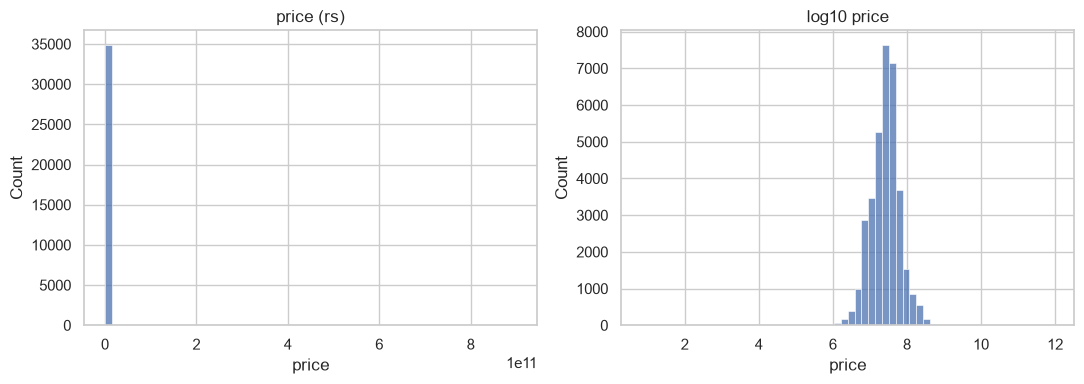

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['price'], bins=60, ax=ax[0])
ax[0].set_title('price (rs)')
sns.histplot(np.log10(df['price']), bins=60, ax=ax[1])
ax[1].set_title('log10 price')
plt.tight_layout()
plt.show()

price is heavily right skewed. most houses are between 10 and 50 million, a few are far above, so i will model the log of price later. the lowest price is rs 7, which is a typing mistake, so i cut price at the 1st and 99th percentile. 687 rows removed, 34,254 left. house size and land size still have zeros and huge values, i come back to them.

In [10]:
low, high = df['price'].quantile([.01, .99])
before = len(df)
df = df[df['price'].between(low, high)].reset_index(drop=True)
print(f'removed {before - len(df)} rows, kept {len(df)}')

removed 687 rows, kept 34254


In [11]:
df.describe().round(1)

,price,bedrooms,bathrooms,house_size_sqft,land_size_perches,is_verified,posted_month
count,34254.0,34254.0,34254.0,34254.0,34254.0,34254.0,34254.0
mean,35622528.2,3.7,2.6,2618.2,21.4,0.6,5.4
std,33443820.0,1.3,1.3,6789.3,411.9,0.5,4.6
min,2750000.0,1.0,1.0,0.0,0.0,0.0,1.0
25%,15000000.0,3.0,2.0,1500.0,7.2,0.0,2.0
50%,26500000.0,4.0,2.0,2205.0,10.0,1.0,3.0
75%,43500000.0,4.0,3.0,3014.0,13.0,1.0,11.0
max,230000000.0,10.0,10.0,900000.0,62500.0,1.0,12.0
